In [2]:
!pip install numpy cython pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.6 MB/s eta 0:00:00a 0:00:01

[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


# Raw Data Description, Cleaning, and Initial EDA
**Project:** Solar filament segmentation (MAGFiLO Kaggle 2026)

Covers: sample size, feature dimensions, class balance (object-level and pixel-level), data cleaning checks, and initial EDA. A summary table at the end can be pasted into the report.

In [3]:
import os, json, glob, random
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
from pycocotools import mask as mask_utils

ROOT = "MAGFiLO_1.0_Kaggle_2026"          # <-- change if needed
TRAIN_IMG_DIR = f"{ROOT}/train/train_images"
TEST_IMG_DIR  = f"{ROOT}/test/test_images"
ANN_PATH = f"{ROOT}/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json"
H = W = 2048
random.seed(0); np.random.seed(0)

## 1. Raw data: sample size

In [4]:
with open(ANN_PATH) as f:
    data = json.load(f)

imgs = pd.DataFrame(data["images"]);       imgs["id"] = imgs["id"].astype(str)
anns = pd.DataFrame(data["annotations"]);  anns["image_id"] = anns["image_id"].astype(str)
cat_names = {c["id"]: c["name"] for c in data["categories"]}
anns["category"] = anns["category_id"].map(cat_names)

imgs["annotator"] = imgs["id"].str.split("-").str[0]
imgs["base"] = imgs["id"].str.split("-").str[-1]
stem = imgs["file_name"].str.rsplit(".", n=1).str[0]
imgs["time"] = pd.to_datetime(stem.str[:14], format="%Y%m%d%H%M%S", errors="coerce")
imgs["instrument"] = stem.str[14:]

test_files = sorted(glob.glob(f"{TEST_IMG_DIR}/*"))

print("TRAIN")
print("  image entries (annotator-specific) :", len(imgs))
print("  unique solar images (base)         :", imgs['base'].nunique())
print("  unique annotators                  :", imgs['annotator'].nunique())
print("  annotated filaments (instances)    :", len(anns))
print("  avg filaments / image entry        :", round(len(anns)/len(imgs), 2))
print("  date range                         :", imgs['time'].min(), "->", imgs['time'].max())
print("  instruments                        :", imgs['instrument'].value_counts().to_dict())
print("TEST")
print("  images                             :", len(test_files))

TRAIN
  image entries (annotator-specific) : 1154
  unique solar images (base)         : 707
  unique annotators                  : 37
  annotated filaments (instances)    : 8199
  avg filaments / image entry        : 7.1
  date range                         : 2011-01-09 10:47:34 -> 2022-08-03 07:47:52
  instruments                        : {'Lh': 210, 'Mh': 205, 'Bh': 198, 'Ch': 195, 'Th': 180, 'Uh': 166}
TEST
  images                             : 180


## 2. Feature dimensions

In [5]:
print("Image sizes in JSON :", imgs.groupby(['width','height']).size().to_dict())

# Verify on disk with a sample
chk = imgs.sample(min(50, len(imgs)), random_state=0)
shapes, dtypes, ranges = set(), set(), []
for fn in chk["file_name"]:
    im = cv2.imread(f"{TRAIN_IMG_DIR}/{fn}", cv2.IMREAD_UNCHANGED)
    shapes.add(im.shape); dtypes.add(str(im.dtype)); ranges.append((im.min(), im.max()))
print("On-disk shapes :", shapes, "| dtypes:", dtypes)
print("Min/Max pixel across sample:", min(r[0] for r in ranges), max(r[1] for r in ranges))
print(f"Features per image: {H}x{W} = {H*W:,} single-channel pixels (8-bit grayscale)")
print("Targets: polygon mask per filament + spine + bbox + class label")

Image sizes in JSON : {(2048, 2048): 1154}
On-disk shapes : {(2048, 2048)} | dtypes: {'uint8'}
Min/Max pixel across sample: 0 255
Features per image: 2048x2048 = 4,194,304 single-channel pixels (8-bit grayscale)
Targets: polygon mask per filament + spine + bbox + class label


## 3. Data cleaning checks

In [6]:
issues = {}

# 3.1 files exist & readable
missing = [fn for fn in imgs["file_name"] if not os.path.exists(f"{TRAIN_IMG_DIR}/{fn}")]
issues["missing image files"] = len(missing)

# 3.2 referential integrity
issues["annotations w/o image"] = int((~anns["image_id"].isin(imgs["id"])).sum())
issues["images w/o annotations"] = int((~imgs["id"].isin(anns["image_id"])).sum())

# 3.3 duplicate ids
issues["duplicate image ids"] = int(imgs["id"].duplicated().sum())
issues["duplicate annotation ids"] = int(anns["id"].duplicated().sum())
issues["duplicate file names"] = int(imgs["file_name"].duplicated().sum())

# 3.4 missing values
issues["null segmentation"] = int(anns["segmentation"].isna().sum())
issues["null/empty spine"] = int(anns["spine"].apply(lambda s: s is None or len(s)==0).sum())
issues["unparsable timestamps"] = int(imgs["time"].isna().sum())

# 3.5 geometry validity
anns["n_pts"] = anns["segmentation"].apply(lambda s: len(s[0])//2 if s and len(s) else 0)
anns["n_polys"] = anns["segmentation"].apply(lambda s: len(s) if s else 0)
issues["polygons with <3 points"] = int((anns["n_pts"] < 3).sum())
issues["annotations with >1 polygon"] = int((anns["n_polys"] > 1).sum())
issues["area <= 0"] = int((anns["area"] <= 0).sum())
issues["iscrowd != 0"] = int((anns["iscrowd"] != 0).sum())

def out_of_bounds(seg):
    p = np.array(seg[0]).reshape(-1,2)
    return (p[:,0].min() < 0) or (p[:,1].min() < 0) or (p[:,0].max() > W) or (p[:,1].max() > H)
valid = anns["n_pts"] >= 3
issues["polygons out of image bounds"] = int(anns.loc[valid, "segmentation"].apply(out_of_bounds).sum())

# 3.6 bbox / area consistency with the polygon (decode to RLE)
def rle_stats(seg):
    rle = mask_utils.merge(mask_utils.frPyObjects(seg, H, W))
    return mask_utils.area(rle), mask_utils.toBbox(rle)
rs = anns.loc[valid, "segmentation"].apply(rle_stats)
anns.loc[valid, "rle_area"] = rs.apply(lambda t: float(t[0]))
anns["area_rel_err"] = (anns["rle_area"] - anns["area"]).abs() / anns["area"].clip(lower=1)
issues["area mismatch (>5% vs RLE)"] = int((anns["area_rel_err"] > 0.05).sum())
issues["very small filaments (<50 px)"] = int((anns["area"] < 50).sum())

pd.Series(issues, name="count").to_frame()

,count
missing image files,0
annotations w/o image,0
images w/o annotations,0
duplicate image ids,0
duplicate annotation ids,0
duplicate file names,447
null segmentation,0
null/empty spine,0
unparsable timestamps,0
polygons with <3 points,0


In [7]:
# 3.7 Exact/near-duplicate annotations inside the same image entry
key = anns["image_id"] + "_" + anns["bbox"].apply(lambda b: tuple(np.round(b,1))).astype(str)
print("Duplicate (image, bbox) annotations:", int(key.duplicated().sum()))

# 3.8 Filaments that overlap heavily within one annotator's image (possible double-drawn)
def pair_overlaps(image_id, thr=0.8):
    g = anns[(anns["image_id"]==image_id) & valid]
    ms = [mask_utils.merge(mask_utils.frPyObjects(s, H, W)) for s in g["segmentation"]]
    n, bad = len(ms), 0
    for i in range(n):
        for j in range(i+1, n):
            iou = mask_utils.iou([ms[i]], [ms[j]], [0])[0][0]
            bad += iou > thr
    return bad
sample_ids = random.sample(list(imgs["id"]), min(200, len(imgs)))
print("Heavily overlapping annotation pairs (IoU>0.8) in 200 sampled images:",
      sum(pair_overlaps(i) for i in sample_ids))

Duplicate (image, bbox) annotations: 0
Heavily overlapping annotation pairs (IoU>0.8) in 200 sampled images: 0


In [8]:
# 3.9 Apply the cleaning: drop broken rows, keep a log
bad = (
    ~anns["image_id"].isin(imgs["id"]) |
    (anns["n_pts"] < 3) | (anns["area"] <= 0) | anns["segmentation"].isna()
)
anns_clean = anns.loc[~bad].copy()
imgs_clean = imgs[~imgs["file_name"].isin(missing)].copy()
print(f"Dropped {bad.sum()} annotations and {len(imgs)-len(imgs_clean)} images")
print(f"Remaining: {len(imgs_clean)} images, {len(anns_clean)} annotations")

# Optional (decide after looking at EDA): remove tiny noise blobs
MIN_AREA = 0   # e.g. 30 to drop sub-30px specks
anns_clean = anns_clean[anns_clean["area"] >= MIN_AREA]

imgs_clean.to_csv("images_clean.csv", index=False)
anns_clean.drop(columns=["segmentation","spine"]).to_csv("annotations_clean_meta.csv", index=False)

Dropped 0 annotations and 0 images
Remaining: 1154 images, 8199 annotations


## 4. Class balance

### 4a. Object-level (category labels)

                count  percent
category                      
Unidentifiable   3074    37.49
Right            2590    31.59
Left             2535    30.92


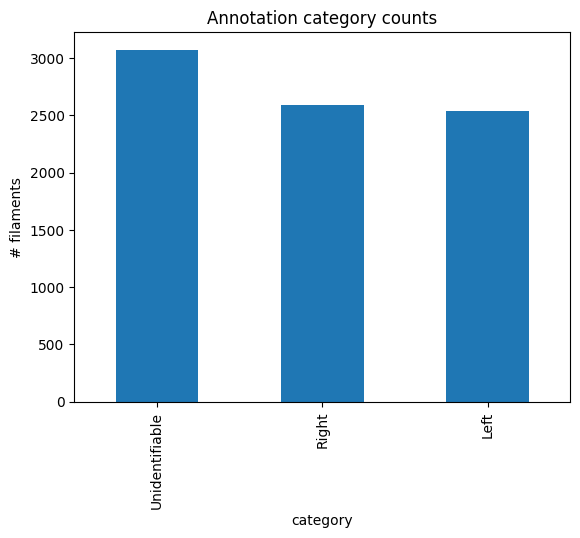


Median area by category (px):
category
Left              1438.0
Right             1524.0
Unidentifiable     868.0
Name: area, dtype: float64


In [9]:
cb = anns_clean["category"].value_counts()
print(pd.DataFrame({"count": cb, "percent": (100*cb/cb.sum()).round(2)}))
cb.plot.bar(title="Annotation category counts"); plt.ylabel("# filaments"); plt.show()

print("\nMedian area by category (px):")
print(anns_clean.groupby("category")["area"].median().round(0))

### 4b. Pixel-level (foreground vs. background)

        fg_total    fg_disk  disk_frac
count  150.00000  150.00000  150.00000
mean     0.00379    0.00497    0.76593
std      0.00312    0.00410    0.02642
min      0.00013    0.00016    0.71392
25%      0.00137    0.00181    0.74496
50%      0.00305    0.00393    0.76544
75%      0.00564    0.00743    0.79455
max      0.01669    0.02198    0.79942

Overall: foreground = 0.379% of all pixels (~1 : 264 FG:BG)
Within the solar disk: 0.497%
Images with NO filament: 0 / 150


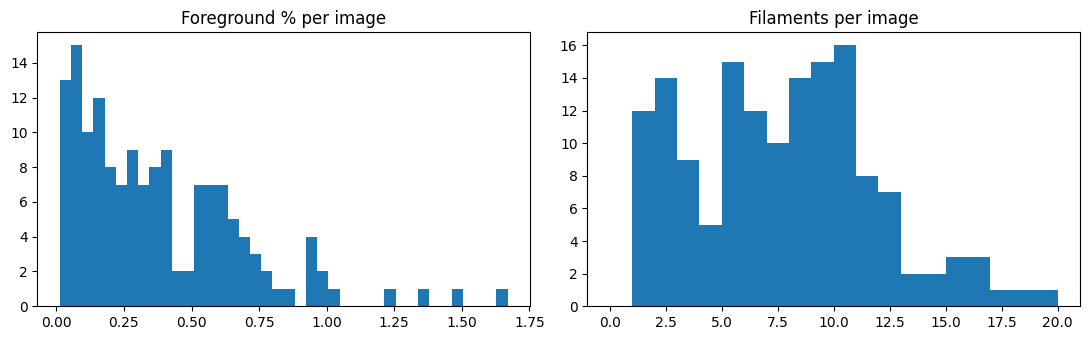

In [10]:
anns_by_img = dict(tuple(anns_clean.groupby("image_id")))

def union_mask(image_id):
    m = np.zeros((H, W), np.uint8)
    for seg in anns_by_img.get(image_id, pd.DataFrame({"segmentation":[]}))["segmentation"]:
        m |= mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(seg, H, W)))
    return m

samp = imgs_clean.sample(min(150, len(imgs_clean)), random_state=0)
rows = []
for _, r in samp.iterrows():
    im = cv2.imread(f"{TRAIN_IMG_DIR}/{r['file_name']}", cv2.IMREAD_GRAYSCALE)
    m = union_mask(r["id"]).astype(bool)
    disk = im > 10                       # rough solar-disk mask
    rows.append({"id": r["id"], "fg_total": m.mean(), "fg_disk": m.sum()/max(disk.sum(),1),
                 "disk_frac": disk.mean(), "n_fil": len(anns_by_img.get(r["id"], []))})
px = pd.DataFrame(rows)
print(px[["fg_total","fg_disk","disk_frac"]].describe().round(5))
print(f"\nOverall: foreground = {100*px['fg_total'].mean():.3f}% of all pixels "
      f"(~1 : {1/px['fg_total'].mean():.0f} FG:BG)")
print(f"Within the solar disk: {100*px['fg_disk'].mean():.3f}%")
print("Images with NO filament:", int((px['n_fil']==0).sum()), "/", len(px))

fig, ax = plt.subplots(1, 2, figsize=(11,3.5))
ax[0].hist(100*px["fg_total"], bins=40); ax[0].set_title("Foreground % per image")
ax[1].hist(px["n_fil"], bins=range(0, px["n_fil"].max()+2)); ax[1].set_title("Filaments per image")
plt.tight_layout(); plt.show()

In [11]:
# Suggested loss weights from the pixel imbalance
fg = px["fg_total"].mean()
print(f"pos_weight for BCE ~ {(1-fg)/fg:.1f}   (start lower, e.g. sqrt of this, then tune)")

pos_weight for BCE ~ 262.7   (start lower, e.g. sqrt of this, then tune)


## 5. Initial EDA

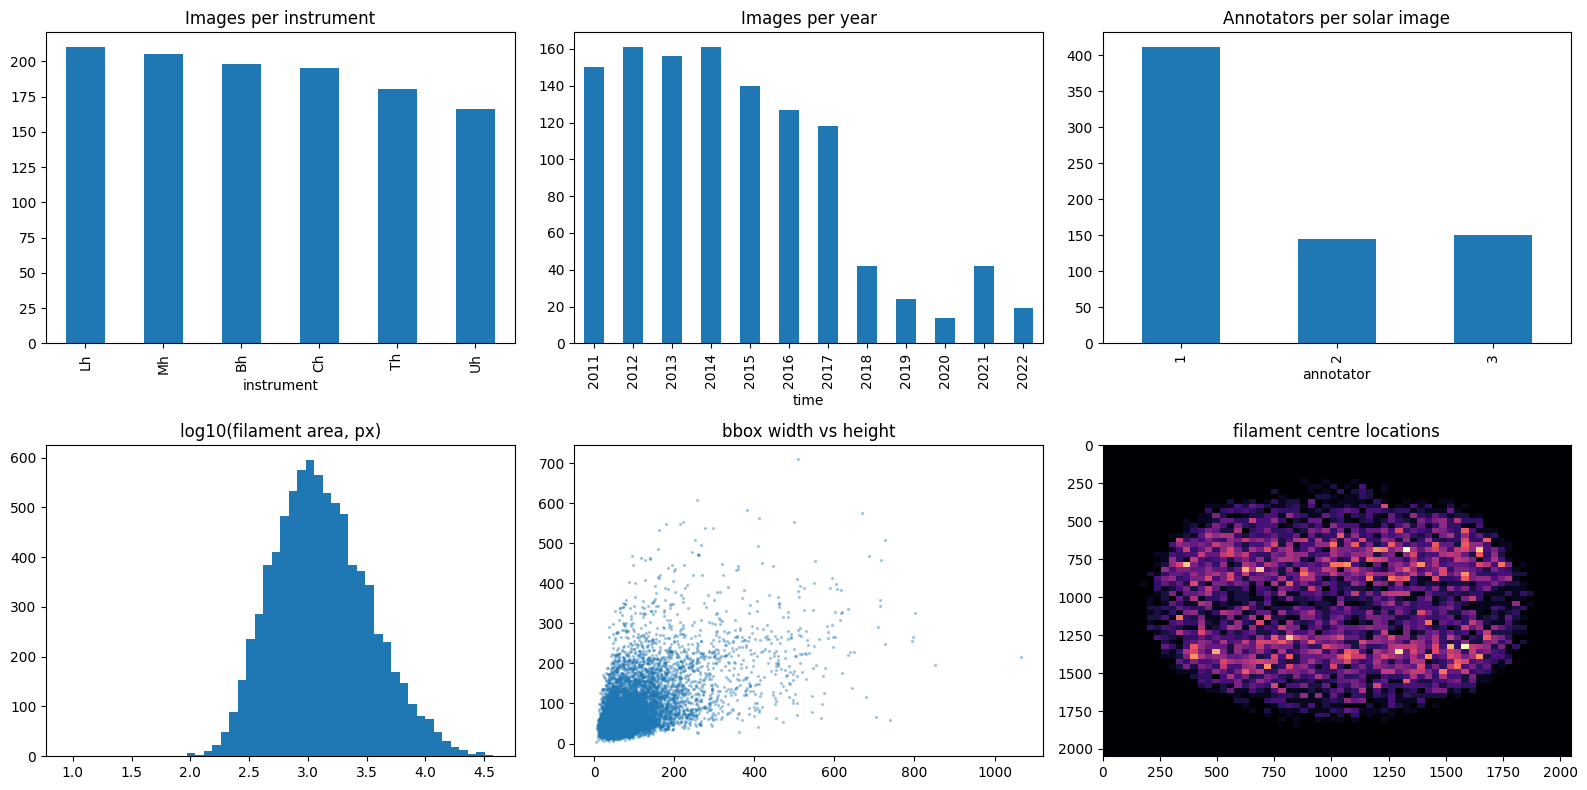

In [12]:
fig, ax = plt.subplots(2, 3, figsize=(16,8))
imgs_clean["instrument"].value_counts().plot.bar(ax=ax[0,0], title="Images per instrument")
imgs_clean["time"].dt.year.value_counts().sort_index().plot.bar(ax=ax[0,1], title="Images per year")
imgs_clean.groupby("base")["annotator"].nunique().value_counts().sort_index().plot.bar(ax=ax[0,2], title="Annotators per solar image")
ax[1,0].hist(np.log10(anns_clean["area"].clip(lower=1)), bins=50); ax[1,0].set_title("log10(filament area, px)")
bb = pd.DataFrame(anns_clean["bbox"].tolist(), columns=["x","y","w","h"])
ax[1,1].scatter(bb["w"], bb["h"], s=2, alpha=0.3); ax[1,1].set_title("bbox width vs height")
cx, cy = bb["x"]+bb["w"]/2, bb["y"]+bb["h"]/2
ax[1,2].hist2d(cx, cy, bins=64, range=[[0,W],[0,H]], cmap="magma"); ax[1,2].invert_yaxis(); ax[1,2].set_title("filament centre locations")
plt.tight_layout(); plt.show()

In [13]:
# Shape: elongation of each filament (long, thin => hard for segmentation)
bb["aspect"] = bb[["w","h"]].max(axis=1) / bb[["w","h"]].min(axis=1).clip(lower=1)
anns_clean = anns_clean.reset_index(drop=True)
anns_clean["aspect"] = bb["aspect"].values
print(anns_clean[["area","aspect"]].describe().round(1))

# Spine length (pixels) as a thinness proxy
def spine_len(s):
    p = np.array(s).reshape(-1,2); return np.linalg.norm(np.diff(p, axis=0), axis=1).sum()
anns_clean["spine_px"] = anns_clean["spine"].apply(lambda s: spine_len(s) if s is not None and len(s)>=4 else np.nan)
anns_clean["mean_width_px"] = anns_clean["area"] / anns_clean["spine_px"]
print(anns_clean[["spine_px","mean_width_px"]].describe().round(1))

          area  aspect
count   8199.0  8199.0
mean    2119.8     2.0
std     2741.7     1.0
min        9.0     1.0
25%      670.0     1.3
50%     1228.0     1.7
75%     2438.0     2.4
max    37739.0    12.8
       spine_px  mean_width_px
count    8199.0         8199.0
mean      147.4           12.7
std       118.9            6.8
min        12.1            0.1
25%        70.6            8.3
50%       111.3           11.1
75%       182.5           15.2
max      1105.0           70.2


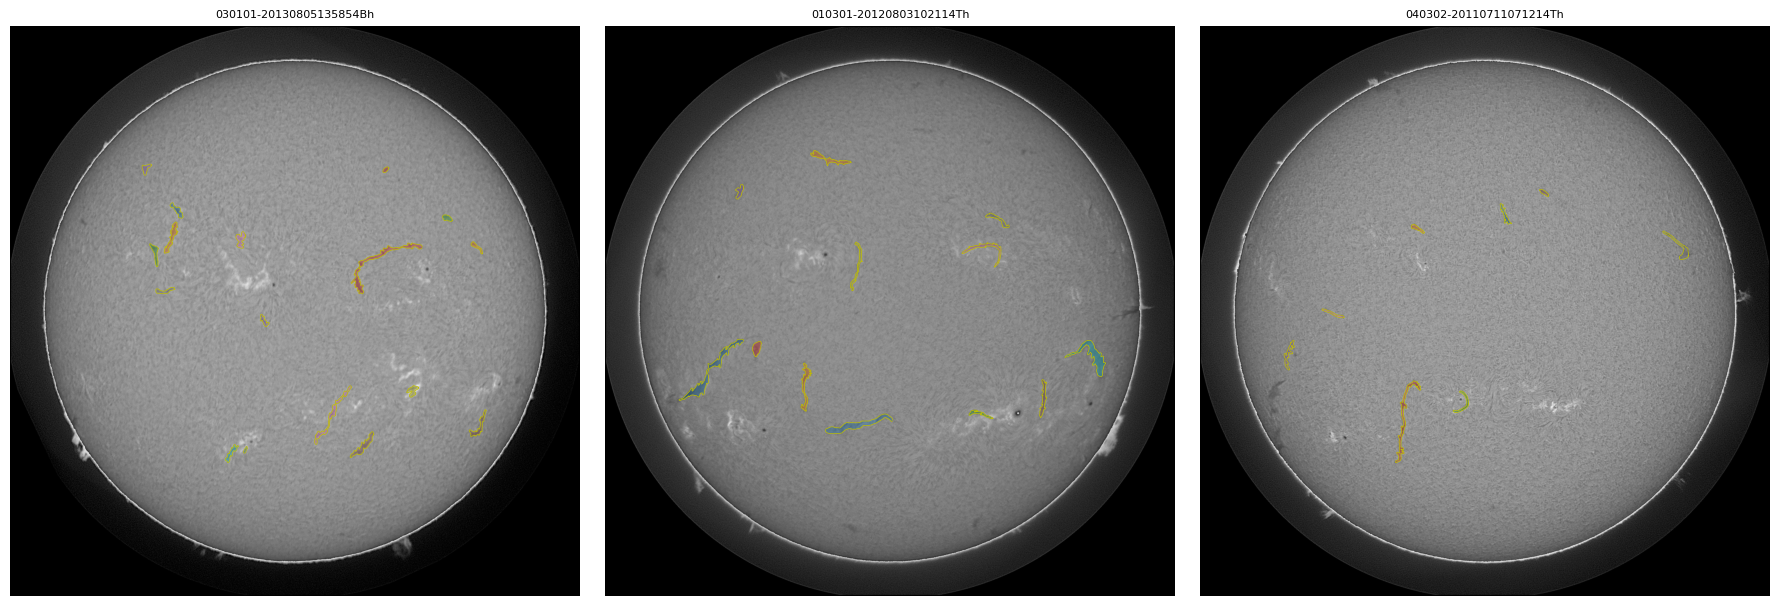

In [14]:
# Visual check: images with overlays
def show(image_id, ax):
    r = imgs_clean[imgs_clean["id"]==image_id].iloc[0]
    im = cv2.imread(f"{TRAIN_IMG_DIR}/{r['file_name']}", cv2.IMREAD_GRAYSCALE)
    ax.imshow(im, cmap="gray")
    for _, a in anns_by_img.get(image_id, pd.DataFrame()).iterrows():
        p = np.array(a["segmentation"][0]).reshape(-1,2)
        ax.fill(p[:,0], p[:,1], alpha=0.35); ax.plot(p[:,0], p[:,1], "y", lw=0.5)
    ax.set_title(image_id, fontsize=8); ax.axis("off")

fig, axs = plt.subplots(1, 3, figsize=(18,6))
for i, ax in zip(random.sample(list(imgs_clean["id"]), 3), axs): show(i, ax)
plt.tight_layout(); plt.show()

Pairs compared: 82 | mean IoU = 0.445 | median = 0.457


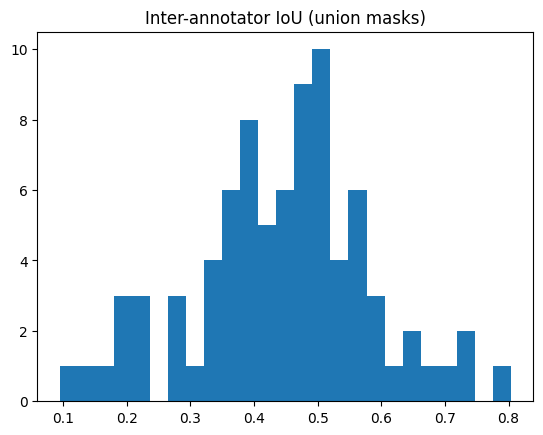

In [15]:
# Annotator agreement on shared images (label noise estimate)
multi = imgs_clean.groupby("base")["id"].apply(list)
multi = multi[multi.apply(len) >= 2]
ious = []
for ids in random.sample(list(multi), min(40, len(multi))):
    ms = [union_mask(i).astype(bool) for i in ids]
    for a in range(len(ms)):
        for b in range(a+1, len(ms)):
            u = (ms[a] | ms[b]).sum()
            if u: ious.append((ms[a] & ms[b]).sum() / u)
print(f"Pairs compared: {len(ious)} | mean IoU = {np.mean(ious):.3f} | median = {np.median(ious):.3f}")
plt.hist(ious, bins=25); plt.title("Inter-annotator IoU (union masks)"); plt.show()

In [16]:
# Intensity statistics per instrument (informs normalization)
rows = []
for _, r in imgs_clean.sample(min(120, len(imgs_clean)), random_state=1).iterrows():
    im = cv2.imread(f"{TRAIN_IMG_DIR}/{r['file_name']}", cv2.IMREAD_GRAYSCALE)
    d = im[im > 10]
    rows.append({"instrument": r["instrument"], "mean": d.mean(), "std": d.std(),
                 "p1": np.percentile(d,1), "p99": np.percentile(d,99)})
print(pd.DataFrame(rows).groupby("instrument").mean().round(1))

             mean   std    p1    p99
instrument                          
Bh          111.2  37.0  20.6  158.9
Ch          111.0  37.3  16.5  159.3
Lh          106.3  40.2  15.9  157.5
Mh          106.5  41.3  17.9  157.8
Th          107.0  35.9  27.8  157.3
Uh          109.6  37.4  18.9  156.3


In [17]:
# Train vs test distribution shift
t = pd.DataFrame({"file_name": [os.path.basename(f) for f in test_files]})
ts = t["file_name"].str.rsplit(".", n=1).str[0]
t["time"] = pd.to_datetime(ts.str[:14], format="%Y%m%d%H%M%S", errors="coerce"); t["instrument"] = ts.str[14:]
cmp = pd.concat({"train": imgs_clean["instrument"].value_counts(normalize=True),
                 "test": t["instrument"].value_counts(normalize=True)}, axis=1).fillna(0).round(3)
print(cmp)
print("Train range:", imgs_clean["time"].min(), "->", imgs_clean["time"].max())
print("Test  range:", t["time"].min(), "->", t["time"].max())
print("Base-name overlap train/test:", len(set(ts) & set(imgs_clean["base"])))

            train   test
instrument              
Lh          0.182  0.189
Mh          0.178  0.144
Bh          0.172  0.183
Ch          0.169  0.183
Th          0.156  0.150
Uh          0.144  0.150
Train range: 2011-01-09 10:47:34 -> 2022-08-03 07:47:52
Test  range: 2011-01-20 10:55:34 -> 2022-07-28 18:53:52
Base-name overlap train/test: 0


## 6. Summary table (for the report)

In [18]:
summary = {
    "Train image entries": len(imgs_clean),
    "Unique solar images": imgs_clean["base"].nunique(),
    "Test images": len(test_files),
    "Annotated filaments": len(anns_clean),
    "Filaments / image (mean)": round(len(anns_clean)/len(imgs_clean), 2),
    "Input dimension": f"{H}x{W}x1 ({H*W:,} px), 8-bit grayscale",
    "Foreground pixels (%)": round(100*px["fg_total"].mean(), 3),
    "FG:BG ratio": f"1:{1/px['fg_total'].mean():.0f}",
    "Median filament area (px)": int(anns_clean["area"].median()),
    "Median mean width (px)": round(anns_clean["mean_width_px"].median(), 1),
    "Inter-annotator IoU (mean)": round(float(np.mean(ious)), 3) if ious else None,
    "Annotations removed in cleaning": int(bad.sum()),
}
pd.Series(summary, name="value").to_frame()

,value
Train image entries,1154
Unique solar images,707
Test images,180
Annotated filaments,8199
Filaments / image (mean),7.1
Input dimension,"2048x2048x1 (4,194,304 px), 8-bit grayscale"
Foreground pixels (%),0.379
FG:BG ratio,1:264
Median filament area (px),1228
Median mean width (px),11.1
